# Lesson 1 — Statistics: the big picture, by simulation

*Companion notebook to the slides. Based on Part 1 of Gelman, Hill & Vehtari, **Regression and Other Stories** (chapters 1–5), with Python instead of R.*

**The idea of this lesson:** before any formula, we *simulate*. If you can write a few lines of code that generate fake data from a model, you can see for yourself what an estimate, a standard error, a confidence interval or a "significant" result really means.

| Section | Topic | Book chapter |
|---|---|---|
| 1 | Why regression? A first look | 1 |
| 2 | Data and measurement | 2 |
| 3 | Probability as a generative model | 3 |
| 4 | Simulating probability models | 5 |
| 5 | Estimates, standard errors, confidence intervals | 4 |
| 6 | Bias and unmodeled uncertainty | 4 |
| 7 | Statistical significance and its traps | 4 |
| 8 | Bootstrap and fake-data simulation | 5 |
| 9 | Regression in pictures: treatment effects, adjustment, interactions | 1 |
| 10 | Averages, weights and aggregation | 2–3 |
| 11 | The mathematical toolkit, numerically | 3 |
| 12 | Small samples and robust summaries | 4–5 |
| 13 | Classical and Bayesian inference | 1 |
| 14 | Exercises | 4–5 |

Runs as is on Google Colab (nothing to install). Every random cell uses a fixed seed, so everybody in the class sees the same numbers.

In [37]:
import matplotlib.pyplot as plt  # plots
import numpy as np  # numbers, arrays and random numbers
import pandas as pd  # data tables
import statsmodels.formula.api as smf  # regression
from scipy import stats  # probability distributions

# Our random number generator. The seed (2026) gives everybody the same "random" numbers.
rng = np.random.default_rng(2026)

### How to read the code

The same few Python tools come back again and again in this notebook:

| Code | What it does |
|---|---|
| `rng.normal(3, 0.5, 1000)` | 1000 random numbers from a normal distribution with mean 3 and sd 0.5 (same idea for `rng.binomial`, `rng.poisson`, `rng.uniform`, `rng.integers`) |
| `ability[group == 0]` | keeps only the values of `ability` for the people in group 0 |
| `np.mean(rolls >= 3)` | the **share** of rolls that are 3 or more (Python counts `True` as 1 and `False` as 0) |
| `for i in range(1000):` | repeats the indented lines below it 1000 times |
| `results.append(x)` | adds `x` at the end of the list `results` |
| `plt.hist(x)`, `plt.scatter(x, y)`, `plt.plot(x, y)` | a histogram, a cloud of points, a line; `plt.show()` displays the plot |

## 1. Why regression? A first look (chapter 1)

The book's opening example: can the **economy predict an election**? For each US presidential election since 1952 we have

* `growth`: average growth of personal income in the years before the election (%),
* `vote`: the share of the vote won by the party of the incumbent president (%).

A regression summarizes how the *average* outcome varies with a predictor.

In [38]:
# The 16 elections (data from the book's website, file hibbs.dat)
hibbs = pd.DataFrame({
    "year":   [1952, 1956, 1960, 1964, 1968, 1972, 1976, 1980,
               1984, 1988, 1992, 1996, 2000, 2004, 2008, 2012],
    "growth": [2.40, 2.89, 0.85, 4.21, 3.02, 3.62, 1.08, -0.39,
               3.86, 2.27, 0.38, 1.04, 2.36, 1.72, 0.10, 0.95],
    "vote":   [44.60, 57.76, 49.91, 61.34, 49.60, 61.79, 48.95, 44.70,
               59.17, 53.94, 46.55, 54.74, 50.27, 51.24, 46.32, 52.00],
})
hibbs

,year,growth,vote
0,1952,2.40,44.60
1,1956,2.89,57.76
2,1960,0.85,49.91
3,1964,4.21,61.34
4,1968,3.02,49.60
5,1972,3.62,61.79
6,1976,1.08,48.95
7,1980,-0.39,44.70
8,1984,3.86,59.17
9,1988,2.27,53.94


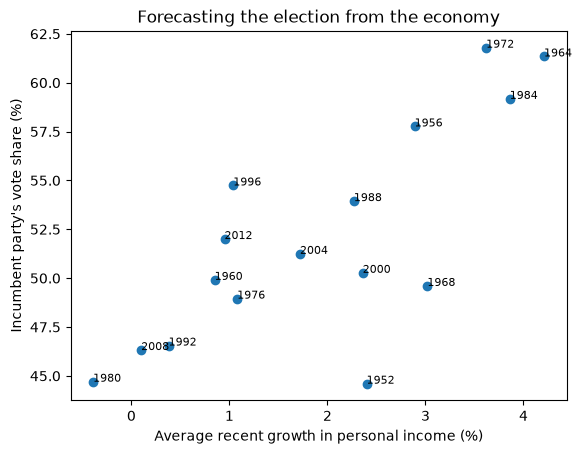

In [39]:
plt.scatter(hibbs["growth"], hibbs["vote"])

# write the year next to each point
for i in range(16):
    plt.text(hibbs["growth"][i], hibbs["vote"][i], hibbs["year"][i], fontsize=8)

plt.xlabel("Average recent growth in personal income (%)")
plt.ylabel("Incumbent party's vote share (%)")
plt.title("Forecasting the election from the economy")
plt.show()

**Fit the line** $y = a + b\,x + \text{error}$ with least squares:

In [40]:
fit = smf.ols("vote ~ growth", data=hibbs).fit()    # least squares: vote = a + b * growth

a = fit.params["Intercept"]       # intercept
b = fit.params["growth"]          # slope
sigma = np.sqrt(fit.mse_resid)    # residual sd: the typical size of a prediction error

print("Fitted line: vote =", round(a, 1), "+", round(b, 1), "* growth")
print("Residual sd: sigma =", round(sigma, 1))

Fitted line: vote = 46.2 + 3.1 * growth
Residual sd: sigma = 3.8


In [103]:
1 - 0.0006099804

0.9993900196

In [101]:
fit.pvalues

Intercept    8.405474e-14
growth       6.099804e-04
dtype: float64

How to read it (the book's output is `46.3`, `3.0` and `3.9`, from a Bayesian fit; classical least squares gives nearly the same):

* **intercept** `a`: predicted vote share when growth is 0.
* **slope** `b`: two elections that differ by 1 point of growth differ, *on average*, by about 3 points of vote share.
* **sigma**: even with the economy known, the prediction is off by about ±4 points. The model gives a *prediction with uncertainty*, never a certainty.

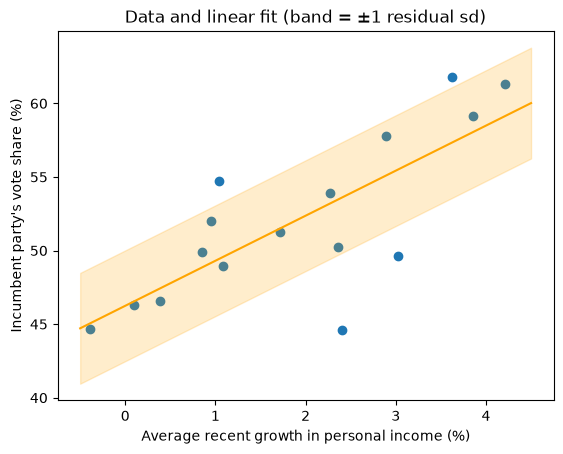

Predicted vote share if growth = 2.0%: 52.4 ± 3.8


In [6]:
x = np.linspace(-0.5, 4.5, 100)    # 100 values of growth, from -0.5 to 4.5
fitted = a + b * x                 # the fitted line at these values

plt.scatter(hibbs["growth"], hibbs["vote"])
plt.plot(x, fitted, color="orange")
# a shaded band from (line - sigma) to (line + sigma); alpha = transparency
plt.fill_between(x, fitted - sigma, fitted + sigma, color="orange", alpha=0.2)
plt.xlabel("Average recent growth in personal income (%)")
plt.ylabel("Incumbent party's vote share (%)")
plt.title("Data and linear fit (band = ±1 residual sd)")
plt.show()

prediction = a + b * 2.0
print("Predicted vote share if growth = 2.0%:", round(prediction, 1), "±", round(sigma, 1))

**Discuss before moving on.** What does this model *not* tell us?
Only 16 elections. Elections are not a random sample of anything. Is "growth → vote" causal, or just an association? These three worries are the **three challenges of statistics** of chapter 1: *sample → population*, *treatment → control*, *measurement → construct*.

## 2. Data and measurement (chapter 2)

Two words that every analyst must separate:

* **Reliability**: if I measure again, do I get the same answer? (*noise*)
* **Validity**: does the measurement capture the thing I actually care about? (*bias*)

We can build both problems on purpose, because we write the "truth" ourselves.

In [7]:
n = 1000
ability = rng.normal(0, 1, n)     # true ability: what we care about (never observed directly)
group = rng.integers(0, 2, n)     # each person is in group 0 or group 1 (same average ability)

test_1 = ability + rng.normal(0, 0.5, n)                 # noisy but fair test
test_2 = ability + rng.normal(0, 0.5, n)                 # the same test, taken again
test_3 = ability - 0.8 * group + rng.normal(0, 0.1, n)   # very precise, but unfair to group 1

# Reliability: do two sittings of test 1 agree?
# np.corrcoef gives a small table of correlations; [0, 1] picks the one we want
correlation = np.corrcoef(test_1, test_2)[0, 1]
print("Correlation between two sittings of test 1:", round(correlation, 2))

# Validity: does each test get the group averages right?
print()
print("Averages of group 0 and group 1:")
print("true ability:", round(np.mean(ability[group == 0]), 2), round(np.mean(ability[group == 1]), 2))
print("test 1:      ", round(np.mean(test_1[group == 0]), 2), round(np.mean(test_1[group == 1]), 2))
print("test 3:      ", round(np.mean(test_3[group == 0]), 2), round(np.mean(test_3[group == 1]), 2))

Correlation between two sittings of test 1: 0.8

Averages of group 0 and group 1:
true ability: -0.01 0.05
test 1:       -0.04 0.03
test 3:       -0.01 -0.74


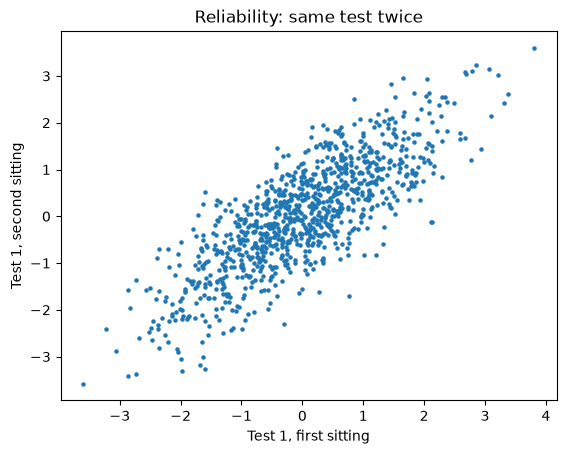

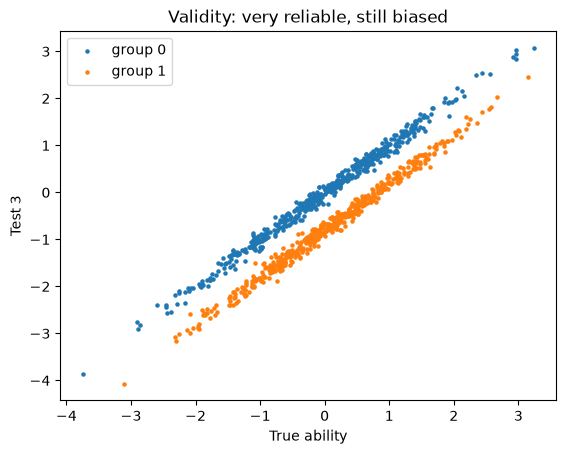

In [8]:
# Reliability: the same test taken twice
plt.scatter(test_1, test_2, s=5)    # s = size of the points
plt.xlabel("Test 1, first sitting")
plt.ylabel("Test 1, second sitting")
plt.title("Reliability: same test twice")
plt.show()

# Validity: test 3 against the true ability, one colour per group
plt.scatter(ability[group == 0], test_3[group == 0], s=5, label="group 0")
plt.scatter(ability[group == 1], test_3[group == 1], s=5, label="group 1")
plt.xlabel("True ability")
plt.ylabel("Test 3")
plt.title("Validity: very reliable, still biased")
plt.legend()
plt.show()

**Take-away.** Test 1 is noisy (correlation 0.8 with itself) but fair: its group averages are about right. Test 3 is almost perfectly repeatable, yet it wrongly says group 1 is less able. *A high-precision measurement of the wrong thing is still wrong*, and more data will never fix it.

## 3. Probability as a generative model (chapter 3)

Probability goes **from a known process to the data it could produce**. The simplest case is a process we fully know: dice.

**The game from the old slides.** Roll one die. Alice gets 1 € if the result is ≥ 3. Bob gets 2 € if the result is ≤ 2. Who do you want to be?

*Vote first, then run the cell.*

In [88]:
# 100,000 rolls of a die: whole numbers from 1 to 6 (the 7 is excluded)
rolls = rng.integers(1, 7, 100000)

alice = np.where(rolls >= 3, 1, 0)   # Alice wins 1 € if the roll is 3 or more, otherwise 0
bob = np.where(rolls <= 2, 2, 0)     # Bob wins 2 € if the roll is 1 or 2, otherwise 0

print("Alice: average gain per game =", round(np.mean(alice), 3), "€")
print("Bob:   average gain per game =", round(np.mean(bob), 3), "€")
print("Exact value for both: 4/6 =", round(4 / 6, 3), "€")

Alice: average gain per game = 0.668 €
Bob:   average gain per game = 0.664 €
Exact value for both: 4/6 = 0.667 €


Same idea with **two dice**: you pick a number between 2 and 12 and win if it is the sum. Which one?

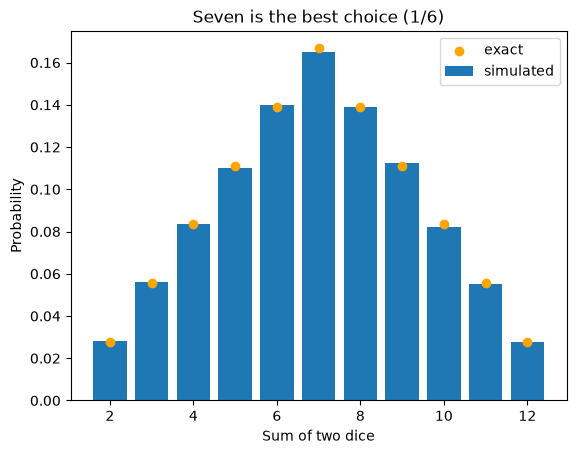

In [10]:
die_1 = rng.integers(1, 7, 100000)
die_2 = rng.integers(1, 7, 100000)
total = die_1 + die_2                      # the sum of the two dice, for 100,000 throws

possible_sums = range(2, 13)               # 2, 3, ..., 12
simulated = []
for s in possible_sums:
    simulated.append(np.mean(total == s))  # share of the throws that gave this sum

# exact probabilities: number of ways to get each sum, out of 36
exact = np.array([1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1]) / 36

plt.bar(possible_sums, simulated, label="simulated")
plt.scatter(possible_sums, exact, color="orange", label="exact")
plt.xlabel("Sum of two dice")
plt.ylabel("Probability")
plt.title("Seven is the best choice (1/6)")
plt.legend()
plt.show()

### A small zoo of distributions
Four distributions cover most of what we need. We draw 1000 values from each (the book's Figure 5.2):

* **Normal**: sums and averages of many small things (heights).
* **Lognormal**: things that multiply (incomes, prices); always positive, skewed.
* **Binomial**: number of successes in *n* independent yes/no trials.
* **Poisson**: counts of rare events (accidents, goals).

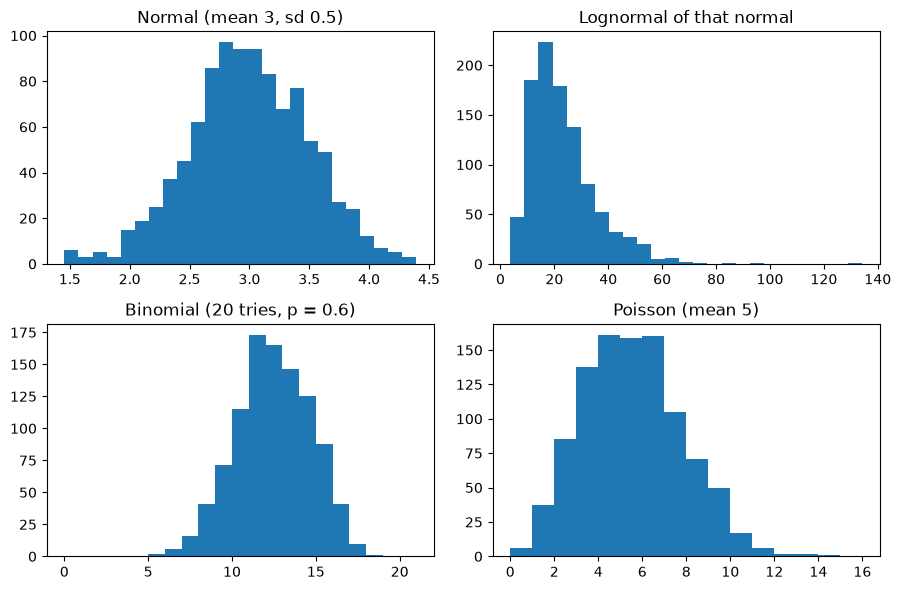

In [11]:
normal_draws = rng.normal(3, 0.5, 1000)
lognormal_draws = np.exp(rng.normal(3, 0.5, 1000))   # exp of a normal = lognormal
binomial_draws = rng.binomial(20, 0.6, 1000)
poisson_draws = rng.poisson(5, 1000)

plt.figure(figsize=(9, 6))     # a bigger figure, for 4 panels

plt.subplot(2, 2, 1)           # panel 1 of a grid with 2 rows and 2 columns
plt.hist(normal_draws, bins=25)
plt.title("Normal (mean 3, sd 0.5)")

plt.subplot(2, 2, 2)
plt.hist(lognormal_draws, bins=25)
plt.title("Lognormal of that normal")

plt.subplot(2, 2, 3)
plt.hist(binomial_draws, bins=range(22))   # one bar per whole number
plt.title("Binomial (20 tries, p = 0.6)")

plt.subplot(2, 2, 4)
plt.hist(poisson_draws, bins=range(17))
plt.title("Poisson (mean 5)")

plt.tight_layout()             # keeps the titles from overlapping
plt.show()

### Why the normal distribution is everywhere: the Central Limit Theorem, by experiment
Add up 20 independent uniform(0, 1) numbers. Individually they are flat, with nothing bell-shaped about them. What does the **sum** look like?

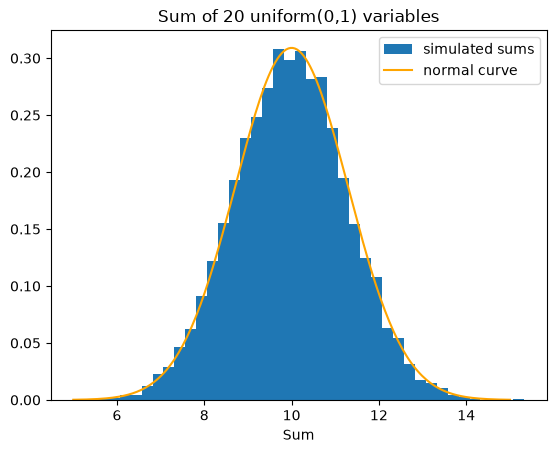

In [12]:
# Add up 20 random numbers between 0 and 1, and do it 10,000 times
sums = []
for i in range(10000):
    numbers = rng.uniform(0, 1, 20)
    sums.append(np.sum(numbers))

# The normal curve, with the mean (20 x 0.5 = 10) and sd (square root of 20/12) of such a sum
x = np.linspace(5, 15, 200)
curve = stats.norm.pdf(x, 10, np.sqrt(20 / 12))

# density=True puts the histogram on the same scale as the curve
plt.hist(sums, bins=40, density=True, label="simulated sums")
plt.plot(x, curve, color="orange", label="normal curve")
plt.xlabel("Sum")
plt.title("Sum of 20 uniform(0,1) variables")
plt.legend()
plt.show()

This is the CLT in one picture: we did not prove anything, we **watched** it. It is the reason a *proportion* or an *average* from a large sample has an approximately normal sampling distribution, which is the key to confidence intervals in section 5.

## 4. Simulating probability models (chapter 5)

**Births.** About 48.8 % of babies are girls. In a hospital with 400 births a year, how many girls?
One simulated year is one draw from a binomial; to see what *could* happen, repeat it many times.

One simulated year: 180 girls


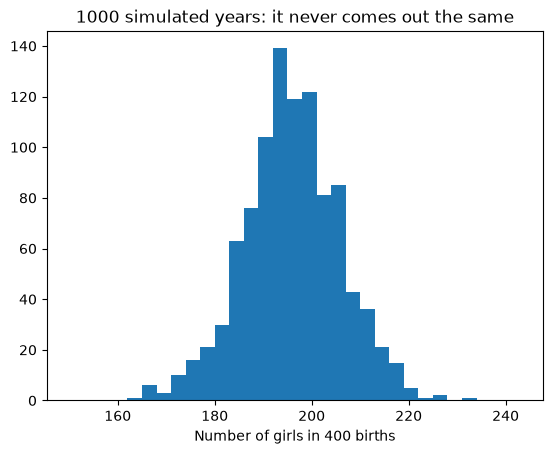

mean = 195.4
sd = 10.0
central 95% interval: from 174.975 to 215.0


In [13]:
one_year = rng.binomial(400, 0.488)        # number of girls in 400 births
print("One simulated year:", one_year, "girls")

n_girls = rng.binomial(400, 0.488, 1000)   # 1000 simulated years

plt.hist(n_girls, bins=range(150, 245, 3))   # bars 3 girls wide
plt.xlabel("Number of girls in 400 births")
plt.title("1000 simulated years: it never comes out the same")
plt.show()

print("mean =", round(np.mean(n_girls), 1))
print("sd =", round(np.std(n_girls), 1))
print("central 95% interval: from", np.percentile(n_girls, 2.5), "to", np.percentile(n_girls, 97.5))

**Making the model more realistic.** 1 birth in 125 is fraternal twins (each ≈ 49.5 % girl), 1 in 300 is identical twins (both girls with prob. ≈ 49.5 %). This is awkward on paper and easy by simulation.

In [14]:
# Number of girls in n_births births, when some births are twins
def simulate_births(n_births):
    # first choose the kind of each birth
    kinds = rng.choice(["fraternal", "identical", "single"],
                       size=n_births,
                       p=[1/125, 1/300, 1 - 1/125 - 1/300])
    n_girls = 0
    for kind in kinds:
        if kind == "single":
            n_girls = n_girls + rng.binomial(1, 0.488)       # one baby: 0 or 1 girl
        elif kind == "identical":
            n_girls = n_girls + 2 * rng.binomial(1, 0.495)   # identical twins: 0 or 2 girls
        else:
            n_girls = n_girls + rng.binomial(2, 0.495)       # fraternal twins: 0, 1 or 2 girls
    return n_girls

n_girls_twins = []
for i in range(1000):
    n_girls_twins.append(simulate_births(400))

print("with twins: mean =", round(np.mean(n_girls_twins), 1))
print("with twins: sd =", round(np.std(n_girls_twins), 1))

with twins: mean = 197.5
with twins: sd = 10.1


**A mixed discrete/continuous model.** 52 % of US adults are women. Heights are normal: men mean 69.1 in, sd 2.9; women mean 63.7 in, sd 2.7. Pick 10 adults at random. What can we say about their **average** and their **maximum** height? Nobody has a formula for the maximum; simulation does not care.

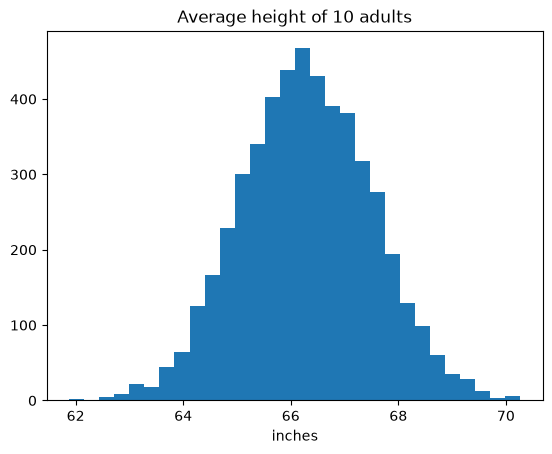

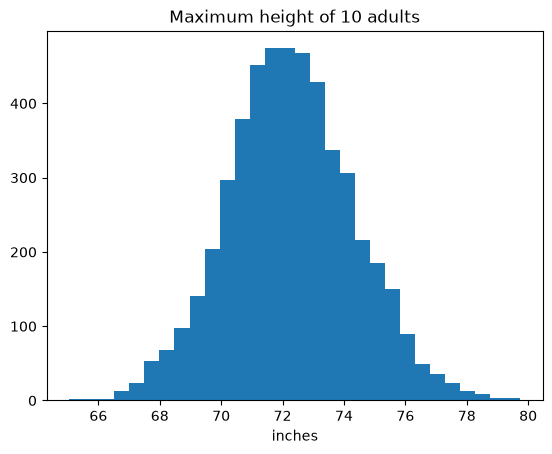

average: mean 66.3   sd 1.21
maximum: mean 72.3   sd 2.07


In [15]:
# Heights (in inches) of n_adults adults picked at random
def simulate_heights(n_adults):
    heights = []
    for i in range(n_adults):
        # rng.random() is a random number between 0 and 1: below 0.52 in 52% of cases
        if rng.random() < 0.52:                    # a woman
            heights.append(rng.normal(63.7, 2.7))
        else:                                      # a man
            heights.append(rng.normal(69.1, 2.9))
    return heights

average_height = []
maximum_height = []
for i in range(5000):
    heights = simulate_heights(10)
    average_height.append(np.mean(heights))
    maximum_height.append(np.max(heights))

plt.hist(average_height, bins=30)
plt.xlabel("inches")
plt.title("Average height of 10 adults")
plt.show()

plt.hist(maximum_height, bins=30)
plt.xlabel("inches")
plt.title("Maximum height of 10 adults")
plt.show()

print("average: mean", round(np.mean(average_height), 1), "  sd", round(np.std(average_height), 2))
print("maximum: mean", round(np.mean(maximum_height), 1), "  sd", round(np.std(maximum_height), 2))

## 5. Estimates, standard errors and confidence intervals (chapter 4)

### 5.1 The head-turning example (from the previous version of this lesson)

*"A neonatal right-side preference makes a surprising romantic reappearance later in life."*
In a published study (Nature, 2003), **80 of 124 kissing couples** turned their head to the right. Let $p$ be the probability that a couple turns right.

* **Estimate:** $\hat p = 80/124 = 64.5\%$.
* **Question:** how much would $\hat p$ change if we could repeat the study? 3 couples out of 5 would also give 60 %... How large must $n$ be?

The answer is the **sampling distribution**: the distribution of $\hat p$ over all the datasets we could have observed. We cannot repeat the real study, but we can repeat a *simulated* one, assuming that the true value is close to what we saw.

p_hat = 0.645
sd of the 10,000 simulated p_hats: 0.0427
standard error from the formula sqrt(p(1-p)/n): 0.043


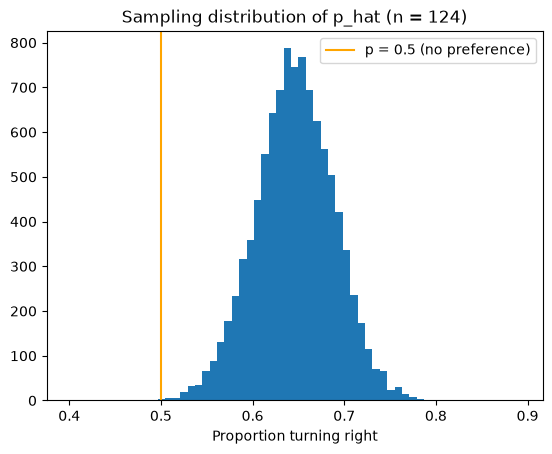

In [98]:
n = 124    # couples observed
y = 80     # couples who turned their head to the right
p_hat = y / n
print("p_hat =", round(p_hat, 3))

# Fake-data simulation: pretend the truth is p = p_hat, and run the study again 10,000 times
p_hats = rng.binomial(n, p_hat, 10000) / n

se_formula = np.sqrt(p_hat * (1 - p_hat) / n)
print("sd of the 10,000 simulated p_hats:", round(np.std(p_hats), 4))
print("standard error from the formula sqrt(p(1-p)/n):", round(se_formula, 4))

# one bar for each possible value of p_hat (they are multiples of 1/124)
plt.hist(p_hats, bins=np.arange(0.4, 0.9, 1/124))
plt.axvline(0.5, color="orange", label="p = 0.5 (no preference)")   # a vertical line
plt.xlabel("Proportion turning right")
plt.title("Sampling distribution of p_hat (n = 124)")
plt.legend()
plt.show()

The spread of this histogram **is** the standard error. The formula $\sqrt{\hat p(1-\hat p)/n}$ is just a shortcut for what the computer did by brute force.

A **95 % confidence interval** is *estimate ± 2 standard errors* (more exactly 1.96):

In [17]:
low = p_hat - 1.96 * se_formula
high = p_hat + 1.96 * se_formula
print("95% interval for p: from", round(low, 3), "to", round(high, 3))
print("Does it contain 0.5 (no preference)?", low <= 0.5 <= high)

95% interval for p: from 0.561 to 0.729
Does it contain 0.5 (no preference)? False


### 5.2 What does "95 %" actually mean? Simulate the coverage
A 95 % interval is a statement about the **procedure**, not about one interval: if we repeated the study again and again, about 95 % of the intervals we compute would contain the true value. We can check, because in a simulation we *know* the truth (the book's Figure 4.2).

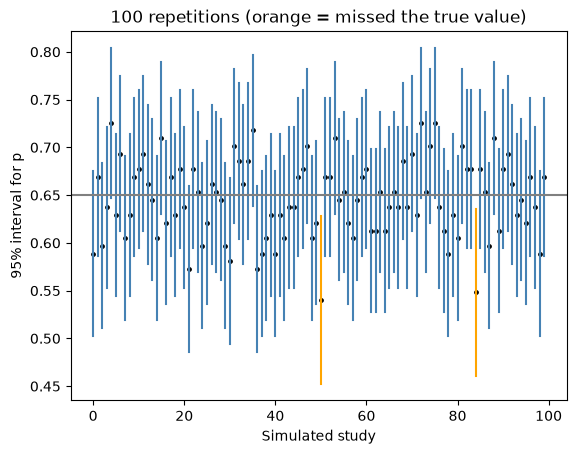

98 of the 100 intervals contain the true value


In [18]:
true_p = 0.65
n = 124
estimates = rng.binomial(n, true_p, 100) / n      # 100 simulated studies
se = np.sqrt(estimates * (1 - estimates) / n)     # the standard error of each estimate
low = estimates - 1.96 * se
high = estimates + 1.96 * se

n_covered = 0
for i in range(100):
    if low[i] <= true_p <= high[i]:      # the interval contains the true value
        n_covered = n_covered + 1
        color = "steelblue"
    else:                                # the interval misses it
        color = "orange"
    plt.plot([i, i], [low[i], high[i]], color=color)   # a vertical line from low to high

plt.scatter(range(100), estimates, s=6, color="black")   # the estimates
plt.axhline(true_p, color="gray")                        # the true value
plt.xlabel("Simulated study")
plt.ylabel("95% interval for p")
plt.title("100 repetitions (orange = missed the true value)")
plt.show()

print(n_covered, "of the 100 intervals contain the true value")

**When does the shortcut fail?** The formula relies on the normal approximation (CLT). Let's measure its real coverage for different sample sizes, and compare with the book's quick fix: use $(y+2)/(n+4)$.

In [19]:
# Share of 20,000 simulated intervals "p_hat ± 1.96 se" that contain the true p
def coverage(true_p, n):
    y = rng.binomial(n, true_p, 20000)
    p_hat = y / n
    se = np.sqrt(p_hat * (1 - p_hat) / n)
    # the interval contains true_p when p_hat is at most 1.96 se away from it
    return np.mean(np.abs(p_hat - true_p) <= 1.96 * se)

# The same, with the book's quick fix: p_hat = (y + 2) / (n + 4)
def coverage_fixed(true_p, n):
    y = rng.binomial(n, true_p, 20000)
    p_hat = (y + 2) / (n + 4)
    se = np.sqrt(p_hat * (1 - p_hat) / (n + 4))
    return np.mean(np.abs(p_hat - true_p) <= 1.96 * se)

for true_p in [0.5, 0.05]:
    for n in [10, 30, 124, 1000]:
        print("true p =", true_p, "  n =", n,
              "  coverage:", round(coverage(true_p, n), 3),
              "  with the fix:", round(coverage_fixed(true_p, n), 3))

true p = 0.5   n = 10   coverage: 0.887   with the fix: 0.978
true p = 0.5   n = 30   coverage: 0.955   with the fix: 0.956
true p = 0.5   n = 124   coverage: 0.939   with the fix: 0.941
true p = 0.5   n = 1000   coverage: 0.944   with the fix: 0.944
true p = 0.05   n = 10   coverage: 0.4   with the fix: 0.988
true p = 0.05   n = 30   coverage: 0.78   with the fix: 0.985
true p = 0.05   n = 124   coverage: 0.942   with the fix: 0.966
true p = 0.05   n = 1000   coverage: 0.941   with the fix: 0.951


For $p=0.5$ the nominal 95 % is nearly right even for small $n$. For a **rare event** ($p=0.05$) and a small sample, the simple interval can miss far more than 5 % of the time (when $y=0$ it even has width zero!). The quick fix helps a lot. *A method has assumptions; simulation is how we check them.*

### 5.3 The standard error shrinks like $1/\sqrt n$
Quadrupling the sample size only halves the uncertainty.

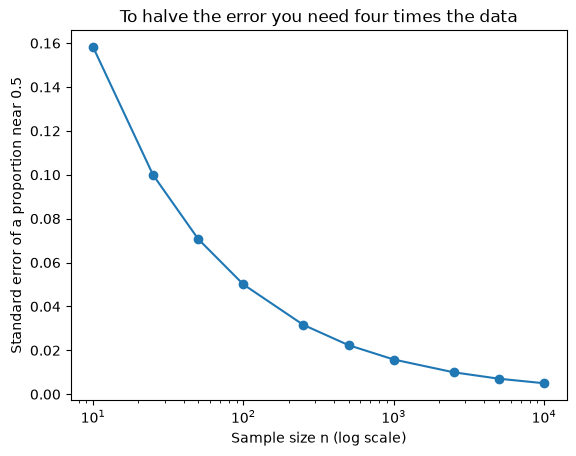

Rule of thumb: se ≈ 0.5 / sqrt(n).
With n = 1000 that's about 1.6 percentage points.


In [20]:
n_values = np.array([10, 25, 50, 100, 250, 500, 1000, 2500, 5000, 10000])
se_values = 0.5 / np.sqrt(n_values)    # standard error of a proportion near 0.5

plt.plot(n_values, se_values, marker="o")
plt.xscale("log")
plt.xlabel("Sample size n (log scale)")
plt.ylabel("Standard error of a proportion near 0.5")
plt.title("To halve the error you need four times the data")
plt.show()

print("Rule of thumb: se ≈ 0.5 / sqrt(n).")
print("With n = 1000 that's about", round(100 * 0.5 / np.sqrt(1000), 1), "percentage points.")

### 5.4 Comparing two groups
The standard error of a **difference** of two independent estimates is $\sqrt{se_1^2 + se_2^2}$.
A survey of 1000 people: 400 men (57 % support a candidate) and 600 women (45 %).

In [21]:
p_men = 0.57
n_men = 400
p_women = 0.45
n_women = 600

se_men = np.sqrt(p_men * (1 - p_men) / n_men)
se_women = np.sqrt(p_women * (1 - p_women) / n_women)

gap = p_men - p_women
se_gap = np.sqrt(se_men**2 + se_women**2)
print("gender gap =", round(gap, 2), "  se =", round(se_gap, 3))
print("95% interval: from", round(gap - 2 * se_gap, 2), "to", round(gap + 2 * se_gap, 2))

# check by simulation
sim_men = rng.binomial(n_men, p_men, 100000) / n_men
sim_women = rng.binomial(n_women, p_women, 100000) / n_women
sim_gap = sim_men - sim_women
print("simulated sd of the difference:", round(np.std(sim_gap), 3))

gender gap = 0.12   se = 0.032
95% interval: from 0.06 to 0.18
simulated sd of the difference: 0.032


### 5.5 Probability vs statistics: the two directions
The two directions that the old slides contrasted, with the drug example, in code.

* **Probability** (model → data): *if the drug cures 80 % of patients*, what do 100 patients look like?
* **Statistics** (data → model): *we saw 78 cured out of 100*, what can we say about the cure rate?

In [22]:
# Probability: the model is known (cure rate 0.80), the data are uncertain
cured = rng.binomial(100, 0.80, 100000)     # 100,000 simulated trials with 100 patients each
print("If p = 0.80: average number cured =", round(np.mean(cured), 1))
print("If p = 0.80: probability of at least 65 cured =", round(np.mean(cured >= 65), 4))

# Statistics: the data are known (78 cured out of 100), the model is uncertain
y = 78
n = 100
p_hat = y / n
se = np.sqrt(p_hat * (1 - p_hat) / n)
print()
print("Observed 78/100 -> p_hat =", p_hat)
print("95% interval: from", round(p_hat - 1.96 * se, 4), "to", round(p_hat + 1.96 * se, 4))

If p = 0.80: average number cured = 80.0
If p = 0.80: probability of at least 65 cured = 0.9998

Observed 78/100 -> p_hat = 0.78
95% interval: from 0.6988 to 0.8612


## 6. Bias and unmodeled uncertainty (chapter 4)

Standard errors only measure **sampling** noise. They say nothing about a sample that is not representative.

**A poll with a biased sample.** True situation: 52 % of the population are women and 48 % men; 60 % of women and 40 % of men support a candidate. The true support is $0.52\times0.6 + 0.48\times0.4 = 50.4\%$.
But women answer the poll twice as often as men (60 % vs 30 % response rate).

In [23]:
share_women = 0.52       # share of women in the population
support_women = 0.60     # support for the candidate among women
support_men = 0.40       # support among men
true_support = share_women * support_women + (1 - share_women) * support_men
print("true support =", round(true_support, 3))

# Women answer the poll twice as often as men...
response_women = 0.60
response_men = 0.30
# ...so among the people who answer, the share of women is larger:
women_answering = share_women * response_women
men_answering = (1 - share_women) * response_men
share_women_in_poll = women_answering / (women_answering + men_answering)
print("women are", round(100 * share_women_in_poll), "% of the respondents (52% of the population)")
print()

# One poll with n respondents: print the naive and the reweighted estimate
def poll(n):
    is_woman = rng.random(n) < share_women_in_poll       # True for each woman in the poll
    prob_yes = np.where(is_woman, support_women, support_men)
    says_yes = rng.random(n) < prob_yes                   # True for each "yes"
    naive = np.mean(says_yes)
    margin = 1.96 * np.sqrt(naive * (1 - naive) / n)      # half-width of the 95% interval
    # reweighting: the support within each group, combined with the POPULATION shares
    yes_women = np.mean(says_yes[is_woman])
    yes_men = np.mean(says_yes[is_woman == False])
    reweighted = share_women * yes_women + (1 - share_women) * yes_men
    print("n =", n, "  naive estimate:", round(naive, 3), "±", round(margin, 3),
          "  reweighted estimate:", round(reweighted, 3))

for n in [600, 6000, 60000, 600000]:
    poll(n)

true support = 0.504
women are 68 % of the respondents (52% of the population)

n = 600   naive estimate: 0.538 ± 0.04   reweighted estimate: 0.519
n = 6000   naive estimate: 0.536 ± 0.013   reweighted estimate: 0.498
n = 60000   naive estimate: 0.539 ± 0.004   reweighted estimate: 0.506
n = 600000   naive estimate: 0.537 ± 0.001   reweighted estimate: 0.504


Look at the results: with more and more data the naive interval becomes extremely narrow, **around the wrong number** (≈ 53.7 % instead of 50.4 %). The reweighted estimate (a *weighted average*, section 3.1 of the book) removes the bias; it still fluctuates a little, because that is sampling noise. More data does not repair a biased design; modeling the difference between sample and population does.

**Adding the unmodeled error.** Past election polls suggest non-sampling error of about 2.5 percentage points. Independent errors add as *variances*: total se $=\sqrt{S_1^2+S_2^2}$.

In [24]:
# all numbers in percentage points
S2 = 2.5                              # non-sampling error
for n in [600, 60000]:
    S1 = 100 * 0.5 / np.sqrt(n)       # sampling standard error
    total = np.sqrt(S1**2 + S2**2)
    print("n =", n, "  sampling se =", round(S1, 2), "  total se =", round(total, 2))

n = 600   sampling se = 2.04   total se = 3.23
n = 60000   sampling se = 0.2   total se = 2.51


A 100× larger sample moves the total uncertainty from 3.2 to 2.5 points. Almost nothing. *Reduce the larger source of error first.*

## 7. Statistical significance and its traps (chapter 4)

Convention: an estimate is "statistically significant" if it is more than about 2 standard errors from zero (p < 0.05). We keep the definition, but we simulate what the habit does to our conclusions.

### 7.1 The significance filter
A (realistic) study of a *small* effect with a *noisy* estimate: the true effect is 0.10 and the standard error is 0.17 (like the Jamaica early-childhood study of the book, where the published estimate was 0.35 ± 0.17).

Mean of ALL estimates: 0.101   (unbiased)
Share of significant studies: 9.2 %   (the 'power')
Mean of |estimate| among significant: 0.409
Exaggeration factor (type M error): 4.1
Wrong sign among significant (type S error): 6.0 %


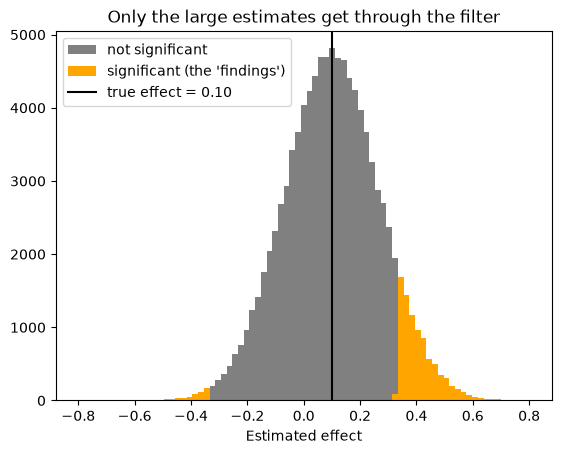

In [25]:
true_effect = 0.10
se = 0.17
estimates = rng.normal(true_effect, se, 100000)   # 100,000 replications of the study
significant = np.abs(estimates) > 1.96 * se       # True if "statistically significant"
significant_estimates = estimates[significant]    # keep only the significant ones
mean_size = np.mean(np.abs(significant_estimates))
wrong_sign = np.mean(significant_estimates < 0)   # share of significant estimates below zero

print("Mean of ALL estimates:", round(np.mean(estimates), 3), "  (unbiased)")
print("Share of significant studies:", round(100 * np.mean(significant), 1), "%   (the 'power')")
print("Mean of |estimate| among significant:", round(mean_size, 3))
print("Exaggeration factor (type M error):", round(mean_size / true_effect, 1))
print("Wrong sign among significant (type S error):", round(100 * wrong_sign, 1), "%")

bins = np.linspace(-0.8, 0.8, 80)       # the same bars for both histograms
plt.hist(estimates[significant == False], bins=bins, color="gray", label="not significant")
plt.hist(significant_estimates, bins=bins, color="orange", label="significant (the 'findings')")
plt.axvline(true_effect, color="black", label="true effect = 0.10")
plt.xlabel("Estimated effect")
plt.title("Only the large estimates get through the filter")
plt.legend()
plt.show()

**This is the most important picture of the lesson.** Each estimate is unbiased, yet the ones that pass the filter are, on average, several times too large, and a few have the wrong sign. If only "significant" results are published, the literature systematically overestimates effects. Noisy studies of small effects *must* produce exaggerated results to reach significance.

### 7.2 "Significant" vs "not significant" is not itself a significant difference
Study 1: 25 ± 10 (significant). Study 2: 10 ± 10 (not significant). Do the studies disagree?

In [26]:
difference = 25 - 10
se_difference = np.sqrt(10**2 + 10**2)
z = difference / se_difference
p_value = 2 * (1 - stats.norm.cdf(z))
print("difference =", difference, "±", round(se_difference, 1))
print("z =", round(z, 2), "  p-value =", round(p_value, 2))

difference = 15 ± 14.1
z = 1.06   p-value = 0.29


### 7.3 Forking paths: noise looks like discovery
Imagine a study with **no real effect at all**, but the analyst has 20 possible outcomes or subgroups to compare (days of the cycle, married or not, which exclusions...). We simulate 2000 such studies, each with two groups of 50 and 20 comparisons of *pure noise*.

In [27]:
# One study with NO real effect: 20 comparisons of two groups of 50 people (pure noise).
# It returns how many of the 20 comparisons look "significant".
def one_study():
    n_significant = 0
    for k in range(20):
        group_a = rng.normal(0, 1, 50)
        group_b = rng.normal(0, 1, 50)
        difference = np.mean(group_a) - np.mean(group_b)
        se = np.sqrt(np.var(group_a) / 50 + np.var(group_b) / 50)
        if np.abs(difference) > 2 * se:       # more than 2 standard errors from zero: "p < 0.05"
            n_significant = n_significant + 1
    return n_significant

results = []
for i in range(2000):
    results.append(one_study())
results = np.array(results)    # a numpy array, so we can compare all the results at once

share_single = np.mean(results) / 20        # share of all comparisons that look "significant"
share_at_least_one = np.mean(results >= 1)  # share of studies with at least one
print("Share of single comparisons with p < 0.05:", round(100 * share_single, 1), "%  (expected: 5%)")
print("Share of studies with AT LEAST ONE p < 0.05:", round(100 * share_at_least_one, 1), "%")
print("Theory: 1 - 0.95**20 =", round(100 * (1 - 0.95**20), 1), "%")

Share of single comparisons with p < 0.05: 5.1 %  (expected: 5%)
Share of studies with AT LEAST ONE p < 0.05: 65.2 %
Theory: 1 - 0.95**20 = 64.2 %


Nobody has to cheat consciously: when the analysis choices depend on the data ("forking paths"), a publishable p-value is easy to find in noise. The book's advice: analyze *all* your data, present *all* your comparisons, accept uncertainty. Don't just demand p < 0.05.

## 8. Bootstrap and fake-data simulation (chapter 5)

### 8.1 The bootstrap: re-run the data collection using the data themselves
We have one dataset and want its sampling distribution. **Resample** the observed rows *with replacement* to create many pseudo-datasets of the same size, recompute the estimate each time, and look at the spread. No formula needed.

Back to the elections: what is the uncertainty on the slope?

slope estimate: 3.06
bootstrap standard error: 0.63
least-squares standard error: 0.7


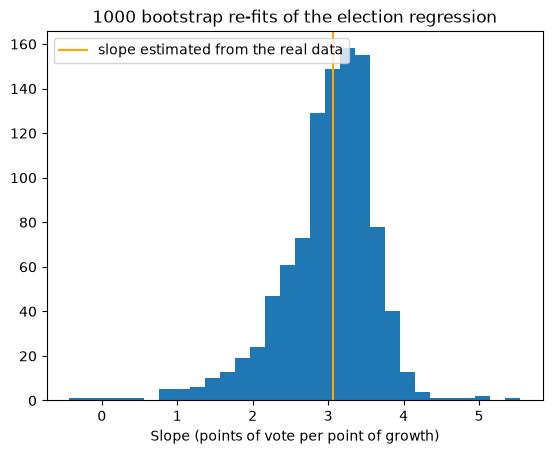

bootstrap 95% interval for the slope: from 1.51 to 3.94


In [28]:
boot_slopes = []
for i in range(1000):
    # 16 elections drawn WITH replacement (random_state=rng: use our random number generator)
    resample = hibbs.sample(16, replace=True, random_state=rng)
    # linregress: a quick straight-line fit (same result as smf.ols, faster inside a loop)
    line = stats.linregress(resample["growth"], resample["vote"])
    boot_slopes.append(line.slope)

print("slope estimate:", round(b, 2))
print("bootstrap standard error:", round(np.std(boot_slopes), 2))
print("least-squares standard error:", round(fit.bse["growth"], 2))

plt.hist(boot_slopes, bins=30)
plt.axvline(b, color="orange", label="slope estimated from the real data")
plt.xlabel("Slope (points of vote per point of growth)")
plt.title("1000 bootstrap re-fits of the election regression")
plt.legend()
plt.show()

low = np.percentile(boot_slopes, 2.5)
high = np.percentile(boot_slopes, 97.5)
print("bootstrap 95% interval for the slope: from", round(low, 2), "to", round(high, 2))

### 8.2 Fake-data simulation: check the method on a world where we know the truth
This is the habit to keep for the whole course. To check a statistical method:
1. **Choose** parameters (here `a = 46.3, b = 3.0, sigma = 3.9`, as in the book).
2. **Simulate** fake data from the model, keeping the real `growth` values.
3. **Fit** the model to the fake data.
4. **Compare** the estimates with the truth, many times.

mean of b_hat over 1000 fake datasets: 3.0   (truth: 3.0)
sd of b_hat (the true standard error): 0.7
coverage of the 95% interval: 95.5 %


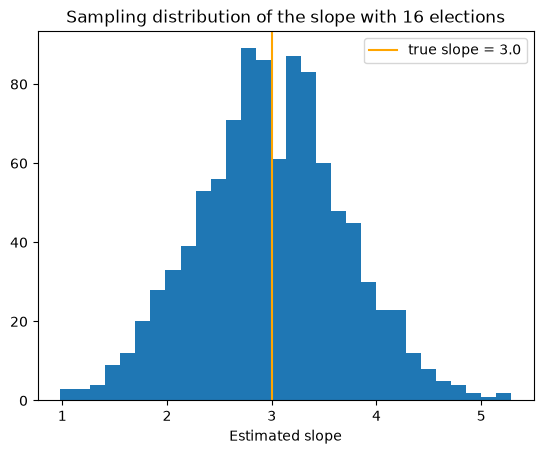

In [29]:
# 1. Choose the true parameters
a_true = 46.3
b_true = 3.0
sigma_true = 3.9
growth = hibbs["growth"]            # we keep the real growth values

# With only 16 points, the 95% interval uses 2.14 instead of 1.96
# (t distribution with 16 - 2 = 14 degrees of freedom, see section 12.1)
t_value = stats.t.ppf(0.975, 14)

b_hats = []
n_covered = 0
for i in range(1000):
    # 2. Simulate fake data from the model
    fake_vote = a_true + b_true * growth + rng.normal(0, sigma_true, 16)
    # 3. Fit the model to the fake data
    line = stats.linregress(growth, fake_vote)
    b_hats.append(line.slope)
    # 4. Compare with the truth: does the 95% interval contain b_true?
    if np.abs(line.slope - b_true) <= t_value * line.stderr:
        n_covered = n_covered + 1

print("mean of b_hat over 1000 fake datasets:", round(np.mean(b_hats), 2), "  (truth: 3.0)")
print("sd of b_hat (the true standard error):", round(np.std(b_hats), 2))
print("coverage of the 95% interval:", round(100 * n_covered / 1000, 1), "%")

plt.hist(b_hats, bins=30)
plt.axvline(b_true, color="orange", label="true slope = 3.0")
plt.xlabel("Estimated slope")
plt.title("Sampling distribution of the slope with 16 elections")
plt.legend()
plt.show()

Now we have **seen** (not been told) that with 16 noisy observations the slope can easily come out anywhere from about 1.5 to 4.5, and that the standard error and 95 % interval formulas do what they promise. Next lessons: linear regression written properly, then logistic regression. The same habit applies to both: *simulate, fit, compare*.

## 9. Regression in pictures (chapter 1)

Four things regression can do. All data in this section are **simulated**, so we know the truth and can check what the regression recovers.

**9.1 Estimating a treatment effect, and the straight line when the truth is curved.**

difference of means = 6.15
regression coefficient = 6.15
its standard error = 1.27
straight-line slope = 2.97 per unit of dose
(an AVERAGE effect over the range of doses)


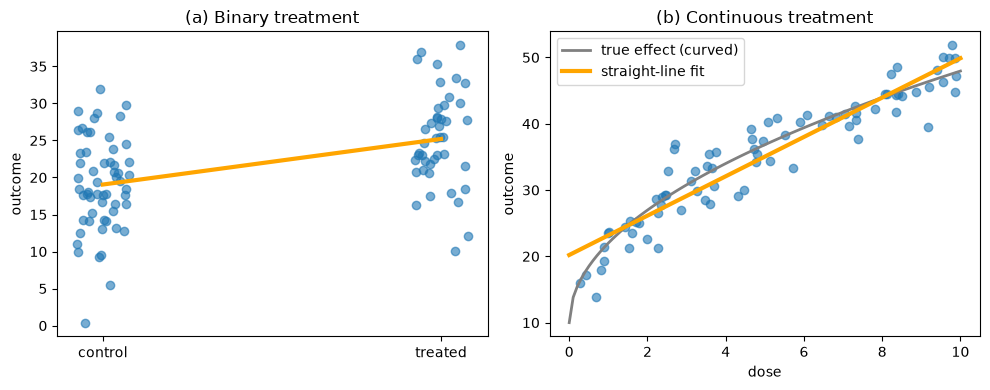

In [30]:
# FIG: reg_causal
rng = np.random.default_rng(101)     # a fixed seed for this figure

# (a) Binary treatment, randomized: regression on a 0/1 variable = difference of means
n = 100
treat = rng.integers(0, 2, n)                # 0 = control, 1 = treated
y = 20 + 5 * treat + rng.normal(0, 6, n)     # true effect of the treatment: +5
data_a = pd.DataFrame({"treat": treat, "y": y})
fit_a = smf.ols("y ~ treat", data=data_a).fit()
difference = np.mean(y[treat == 1]) - np.mean(y[treat == 0])
print("difference of means =", round(difference, 2))
print("regression coefficient =", round(fit_a.params["treat"], 2))
print("its standard error =", round(fit_a.bse["treat"], 2))

# (b) Continuous treatment whose true effect is NOT a straight line (diminishing returns)
dose = rng.uniform(0, 10, 80)
response = 10 + 12 * np.sqrt(dose) + rng.normal(0, 3, 80)
data_b = pd.DataFrame({"dose": dose, "response": response})
fit_b = smf.ols("response ~ dose", data=data_b).fit()
print("straight-line slope =", round(fit_b.params["dose"], 2), "per unit of dose")
print("(an AVERAGE effect over the range of doses)")

plt.figure(figsize=(10, 4))

# left panel (a)
plt.subplot(1, 2, 1)
jitter = rng.uniform(-0.08, 0.08, n)          # small random shifts, so the points don't overlap
plt.scatter(treat + jitter, y, alpha=0.6)
plt.plot([0, 1], [np.mean(y[treat == 0]), np.mean(y[treat == 1])], color="orange", linewidth=3)
plt.xticks([0, 1], ["control", "treated"])
plt.ylabel("outcome")
plt.title("(a) Binary treatment")

# right panel (b)
plt.subplot(1, 2, 2)
x = np.linspace(0, 10, 100)
true_curve = 10 + 12 * np.sqrt(x)
straight_line = fit_b.params["Intercept"] + fit_b.params["dose"] * x
plt.scatter(dose, response, alpha=0.6)
plt.plot(x, true_curve, color="gray", linewidth=2, label="true effect (curved)")
plt.plot(x, straight_line, color="orange", linewidth=3, label="straight-line fit")
plt.xlabel("dose")
plt.ylabel("outcome")
plt.title("(b) Continuous treatment")
plt.legend()

plt.tight_layout()
plt.show()

**9.2 Adjusting for pre-treatment differences, and interactions.**

(c) A remedial program is given mostly to students who did *badly* before. A raw comparison of the final scores is then misleading; the regression compares like with like. (d) An **interaction**: the effect of exposure depends on another variable (here, smoking).

raw difference of means = -5.7   (true effect = 8)
adjusted for the pre-test = 6.8
its standard error = 0.8
mean pre-test of the treated = 40.0
mean pre-test of the controls = 54.1
Intercept      0.98
radon          0.16
smoke         -0.22
radon:smoke    0.53
dtype: float64


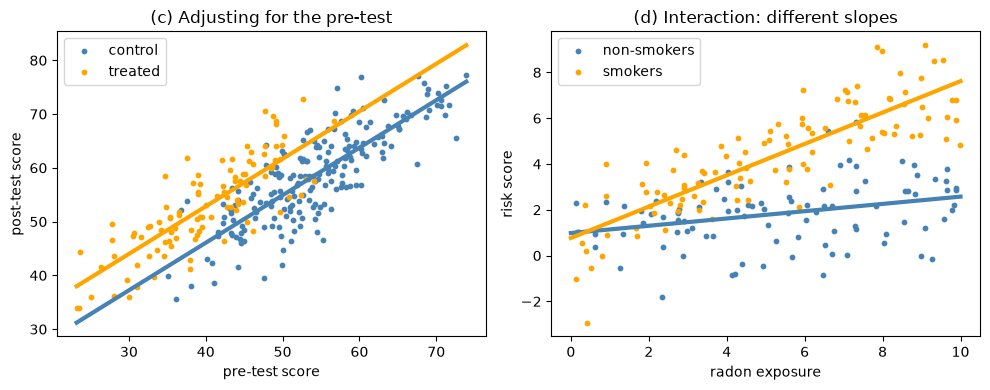

In [31]:
# FIG: reg_adjust
rng = np.random.default_rng(102)     # a fixed seed for this figure

# (c) A remedial program, given mostly to students with LOW pre-test scores
n = 300
pre = rng.normal(50, 10, n)                                   # pre-test scores
prob_treated = 1 / (1 + np.exp((pre - 45) / 5))               # low pre-test: likely treated
treat = np.where(rng.uniform(0, 1, n) < prob_treated, 1, 0)   # 1 = treated, 0 = control
post = 10 + 0.9 * pre + 8 * treat + rng.normal(0, 5, n)       # true effect of the program: +8

data_c = pd.DataFrame({"pre": pre, "treat": treat, "post": post})
fit_c = smf.ols("post ~ pre + treat", data=data_c).fit()
raw_difference = np.mean(post[treat == 1]) - np.mean(post[treat == 0])
print("raw difference of means =", round(raw_difference, 1), "  (true effect = 8)")
print("adjusted for the pre-test =", round(fit_c.params["treat"], 1))
print("its standard error =", round(fit_c.bse["treat"], 1))
print("mean pre-test of the treated =", round(np.mean(pre[treat == 1]), 1))
print("mean pre-test of the controls =", round(np.mean(pre[treat == 0]), 1))

# (d) Interaction: the effect of radon depends on smoking
m = 200
radon = rng.uniform(0, 10, m)
smoke = rng.integers(0, 2, m)                                       # 1 = smoker, 0 = non-smoker
# true slope: 0.15 for non-smokers, 0.15 + 0.45 = 0.60 for smokers
risk = 1 + (0.15 + 0.45 * smoke) * radon + rng.normal(0, 1.2, m)
data_d = pd.DataFrame({"risk": risk, "radon": radon, "smoke": smoke})
fit_d = smf.ols("risk ~ radon * smoke", data=data_d).fit()
print(round(fit_d.params, 2))

plt.figure(figsize=(10, 4))

# left panel (c): one line per group, same slope
plt.subplot(1, 2, 1)
plt.scatter(pre[treat == 0], post[treat == 0], s=10, color="steelblue", label="control")
plt.scatter(pre[treat == 1], post[treat == 1], s=10, color="orange", label="treated")
x = np.linspace(np.min(pre), np.max(pre), 100)
line_control = fit_c.params["Intercept"] + fit_c.params["pre"] * x
line_treated = line_control + fit_c.params["treat"]           # shifted up by the treatment effect
plt.plot(x, line_control, color="steelblue", linewidth=3)
plt.plot(x, line_treated, color="orange", linewidth=3)
plt.xlabel("pre-test score")
plt.ylabel("post-test score")
plt.title("(c) Adjusting for the pre-test")
plt.legend()

# right panel (d): one line per group, different slopes
plt.subplot(1, 2, 2)
plt.scatter(radon[smoke == 0], risk[smoke == 0], s=10, color="steelblue", label="non-smokers")
plt.scatter(radon[smoke == 1], risk[smoke == 1], s=10, color="orange", label="smokers")
x = np.linspace(0, 10, 100)
line_non_smokers = fit_d.params["Intercept"] + fit_d.params["radon"] * x
line_smokers = line_non_smokers + fit_d.params["smoke"] + fit_d.params["radon:smoke"] * x
plt.plot(x, line_non_smokers, color="steelblue", linewidth=3)
plt.plot(x, line_smokers, color="orange", linewidth=3)
plt.xlabel("radon exposure")
plt.ylabel("risk score")
plt.title("(d) Interaction: different slopes")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Averages, weights and aggregation (chapters 2–3)

**10.1 Weighted averages.** The average age in North America is *not* the average of the three country averages: each country must be weighted by its population. The same trap appears in the teachers' pay example.

In [32]:
population = np.array([310, 112, 34])        # millions: US, Mexico, Canada
average_age = np.array([36.8, 26.7, 40.7])
weights = population / np.sum(population)     # each country's share of the population
print("weights:", np.round(weights, 4))
print("weighted average age =", round(np.sum(weights * average_age), 1))
print("naive average of the three =", round(np.mean(average_age), 1))
print()

share_women_teachers = 0.79
pay_women = 45865
pay_men = 49207
average_pay = share_women_teachers * pay_women + (1 - share_women_teachers) * pay_men
print("average pay of teachers =", round(average_pay))
print("naive average of the two =", round((pay_women + pay_men) / 2))

weights: [0.6798 0.2456 0.0746]
weighted average age = 34.6
naive average of the three = 34.7

average pay of teachers = 46567
naive average of the two = 47536


**10.2 Age adjustment (a Simpson-type story).** Suppose the death rate *at each age* does not change at all over 15 years, but the group "45 to 54" gets older on average (the large cohorts move through it). The raw group rate goes up although nobody is at higher risk. Fixing the age mix (here at year 0) removes the artefact. Synthetic numbers, same logic as the study of middle-aged mortality.

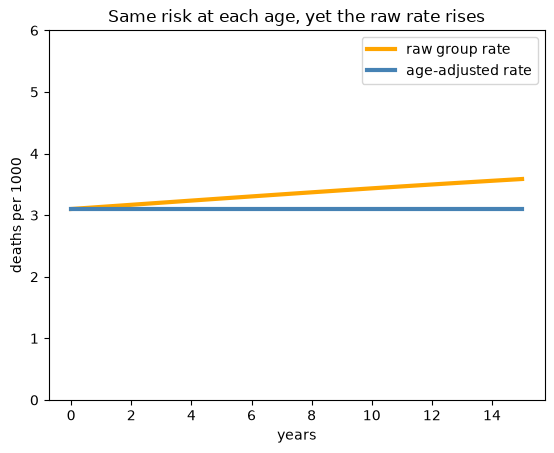

raw rate rises 16 %
adjusted rate changes 0 %


In [33]:
# FIG: mortality
ages = np.arange(45, 55)                          # the ages 45, 46, ..., 54
death_rate = 2.0 * np.exp(0.09 * (ages - 45))     # deaths per 1000 at each age: the SAME every year
share_year_0 = np.ones(10) / 10                   # in year 0, each age is 1/10 of the group

raw_rates = []
adjusted_rates = []
for year in range(16):
    # the age mix drifts towards the older ages
    share = share_year_0 * np.exp(0.015 * year * (ages - 45))
    share = share / np.sum(share)                              # the shares add up to 1
    raw_rates.append(np.sum(share * death_rate))               # with this year's age mix
    adjusted_rates.append(np.sum(share_year_0 * death_rate))   # with the age mix of year 0

plt.plot(range(16), raw_rates, color="orange", linewidth=3, label="raw group rate")
plt.plot(range(16), adjusted_rates, color="steelblue", linewidth=3, label="age-adjusted rate")
plt.ylim(0, 6)
plt.xlabel("years")
plt.ylabel("deaths per 1000")
plt.title("Same risk at each age, yet the raw rate rises")
plt.legend()
plt.show()

# [0] is the first year, [-1] is the last year
print("raw rate rises", round(100 * (raw_rates[-1] / raw_rates[0] - 1)), "%")
print("adjusted rate changes", round(100 * (adjusted_rates[-1] / adjusted_rates[0] - 1)), "%")

## 11. The mathematical toolkit, numerically (chapter 3)

**11.1 Lines, logs and power laws.** A fitted line like `record = 1007 - 0.393 * year` has an intercept (year 0) that means nothing: recenter. Taking logs turns multiplication into addition, so a power law $y = a x^b$ becomes a straight line on a log-log plot.

year, record, record from the recentred formula (seconds):
1900 260 260
1950 241 240
2000 221 221
doubling the mass multiplies the rate by 1.67
multiplying the mass by 10 multiplies the rate by 5.5


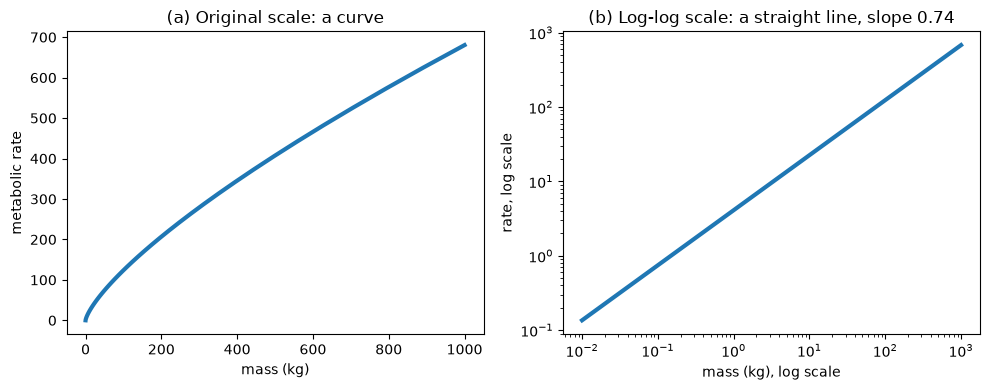

In [34]:
# FIG: powerlaw
# Mile-run world record (in seconds) = 1007 - 0.393 * year
# Recentred: the same line, with 1900 as the starting point
print("year, record, record from the recentred formula (seconds):")
for year in [1900, 1950, 2000]:
    record = 1007 - 0.393 * year
    recentred = 260 - 0.393 * (year - 1900)
    print(year, round(record), round(recentred))

# Metabolic rate = 4.1 * mass^0.74
print("doubling the mass multiplies the rate by", round(2 ** 0.74, 2))
print("multiplying the mass by 10 multiplies the rate by", round(10 ** 0.74, 2))

# 100 masses from 0.01 kg to 1000 kg, evenly spaced on a log scale
mass = np.logspace(-2, 3, 100)
metabolic_rate = 4.1 * mass ** 0.74

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(mass, metabolic_rate, linewidth=3)
plt.xlabel("mass (kg)")
plt.ylabel("metabolic rate")
plt.title("(a) Original scale: a curve")

plt.subplot(1, 2, 2)
plt.plot(mass, metabolic_rate, linewidth=3)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("mass (kg), log scale")
plt.ylabel("rate, log scale")
plt.title("(b) Log-log scale: a straight line, slope 0.74")

plt.tight_layout()
plt.show()

**11.2 The normal distribution: 68-95-99.7, and when it fails.** Heights of women are close to normal; heights of *all adults* are a mixture of two normals and are not.

within 1 sd: 0.683
within 2 sd: 0.954
within 3 sd: 0.997
within 0.67 sd: 0.497


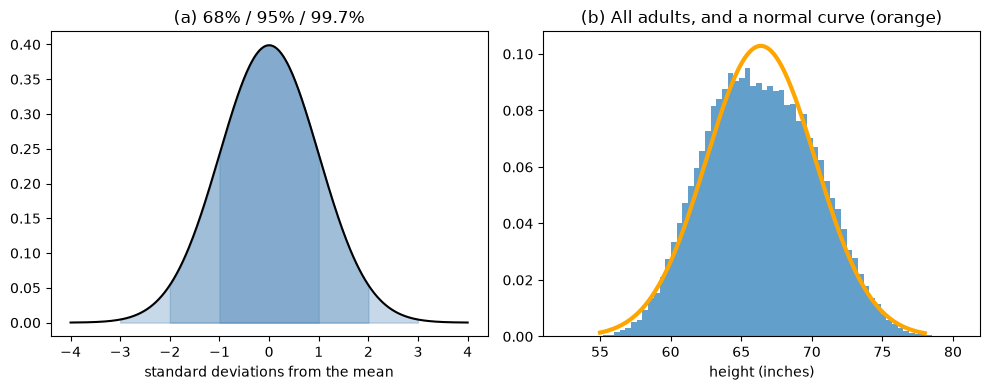

In [35]:
# FIG: normal_mix
rng = np.random.default_rng(111)     # a fixed seed for this figure

# share of a normal distribution within k standard deviations of the mean
for k in [1, 2, 3]:
    share = stats.norm.cdf(k) - stats.norm.cdf(-k)
    print("within", k, "sd:", round(share, 3))
print("within 0.67 sd:", round(stats.norm.cdf(0.67) - stats.norm.cdf(-0.67), 3))

women = rng.normal(63.7, 2.7, 50000)    # heights of 50,000 women (inches)
men = rng.normal(69.1, 2.9, 50000)      # heights of 50,000 men
adults = np.append(women, men)          # all 100,000 adults together

plt.figure(figsize=(10, 4))

# left panel (a): the normal curve, shaded within 1, 2 and 3 sd
plt.subplot(1, 2, 1)
z = np.linspace(-4, 4, 400)
plt.plot(z, stats.norm.pdf(z), color="black")
for k in [1, 2, 3]:
    inside = np.linspace(-k, k, 200)    # the values within k sd of the mean
    plt.fill_between(inside, stats.norm.pdf(inside), color="steelblue", alpha=0.3)
plt.xlabel("standard deviations from the mean")
plt.title("(a) 68% / 95% / 99.7%")

# right panel (b): all adults, against a normal curve with the same mean and sd
plt.subplot(1, 2, 2)
plt.hist(adults, bins=70, density=True, alpha=0.7)
x = np.linspace(55, 78, 300)
plt.plot(x, stats.norm.pdf(x, np.mean(adults), np.std(adults)), color="orange", linewidth=3)
plt.xlabel("height (inches)")
plt.title("(b) All adults, and a normal curve (orange)")

plt.tight_layout()
plt.show()

**11.3 Lognormal, binomial, Poisson: the formulas against the simulation.**

In [35]:
rng = np.random.default_rng(112)     # a fixed seed for this cell

# Lognormal: weights of men, log(weight) is normal with mean 5.13 and sd 0.17
print("geometric mean =", round(np.exp(5.13)), "lb")
print("geometric sd =", round(np.exp(0.17), 2))
print("so 68% of men weigh between (median / 1.19) and (median x 1.19)")
print()

# Binomial: 20 shots, each a success with probability 0.3
n_shots = 20
p_success = 0.3
sim = rng.binomial(n_shots, p_success, 100000)
sd_formula = np.sqrt(n_shots * p_success * (1 - p_success))
print("mean: formula n*p =", n_shots * p_success, "  simulation =", round(np.mean(sim), 2))
print("sd: formula sqrt(n*p*(1-p)) =", round(sd_formula, 2), "  simulation =", round(np.std(sim), 2))
print()

# Poisson: 750 people, each with a 1% chance of being named Michael -> 7.5 Michaels expected
expected = 7.5
print("Poisson(7.5): P(0) =", round(stats.poisson.pmf(0, expected), 4))
print("Poisson(7.5): P(15 or more) =", round(1 - stats.poisson.cdf(14, expected), 4))

geometric mean = 169 lb
geometric sd = 1.19
so 68% of men weigh between (median / 1.19) and (median x 1.19)

mean: formula n*p = 6.0   simulation = 5.99
sd: formula sqrt(n*p*(1-p)) = 2.05   simulation = 2.05

Poisson(7.5): P(0) = 0.0006
Poisson(7.5): P(15 or more) = 0.0103


**11.4 Effect sizes against the spread of the data (stents), and a probability model that breaks (the decisive vote).**

In [36]:
# A treatment adds 20 seconds to treadmill time; patients have mean 510 s and sd 190 s.
percentile = 100 * stats.norm.cdf(20 / 190)
print("a median patient (percentile 50) moves to percentile", round(percentile))
print()

# Probability that one vote decides an election with 200,000 voters
# (in the results, e-05 means "times 10 to the power -5", i.e. 0.00005)
n = 200000
print("forecast normal(0.49, 0.04):", round(stats.norm.pdf(0.5, 0.49, 0.04) / n, 7))
print("forecast normal(0.50, 0.20):", round(stats.norm.pdf(0.5, 0.50, 0.20) / n, 8))

tie_050 = stats.binom.pmf(100000, n, 0.50)    # probability of an exact tie if p = 0.50
print("binomial, p = 0.50:", round(tie_050, 5), "  about 1 in", round(1 / tie_050))

tie_049 = stats.binom.pmf(100000, n, 0.49)    # probability of an exact tie if p = 0.49
print("binomial, p = 0.49:", tie_049, "  absurdly small: the model ignores the uncertainty in p")

a median patient (percentile 50) moves to percentile 54

forecast normal(0.49, 0.04): 4.83e-05
forecast normal(0.50, 0.20): 9.97e-06
binomial, p = 0.50: 0.00178   about 1 in 560
binomial, p = 0.49: 7.519171007280229e-21   absurdly small: the model ignores the uncertainty in p


## 12. Small samples and robust summaries (chapters 4–5)

**12.1 The t distribution.** With only five measurements the standard error is itself uncertain, so the normal interval is too narrow. We use the t distribution with n - 1 degrees of freedom.

mean = 35.8   se = 0.73
normal 95% interval: from 34.4 to 37.2
t 95% interval: from 33.8 to 37.8   (t value 2.78 instead of 1.96)
coverage with n = 5: normal 0.878   t 0.9486


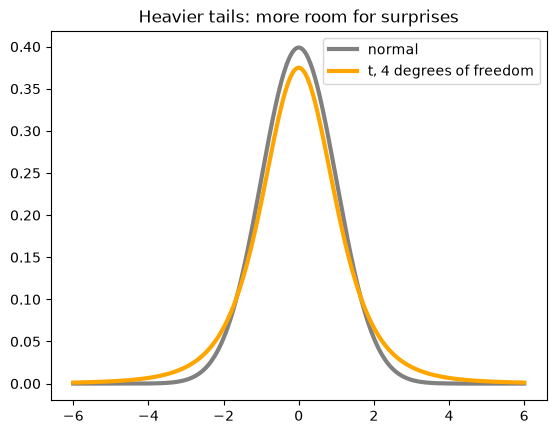

In [37]:
# FIG: t_vs_normal
rng = np.random.default_rng(121)     # a fixed seed for this figure

measurements = np.array([35, 34, 38, 35, 37])
mean = np.mean(measurements)
se = np.std(measurements, ddof=1) / np.sqrt(5)   # ddof=1: the usual sample sd (divide by n - 1)
t_value = stats.t.ppf(0.975, 4)                  # t distribution with 5 - 1 = 4 degrees of freedom
print("mean =", round(mean, 1), "  se =", round(se, 2))
print("normal 95% interval: from", round(mean - 1.96 * se, 1), "to", round(mean + 1.96 * se, 1))
print("t 95% interval: from", round(mean - t_value * se, 1), "to", round(mean + t_value * se, 1),
      "  (t value", round(t_value, 2), "instead of 1.96)")

# Coverage by simulation: 20,000 samples of size 5 from a normal distribution with mean 0
covered_normal = 0
covered_t = 0
for i in range(20000):
    sample = rng.normal(0, 1, 5)
    sample_mean = np.mean(sample)
    sample_se = np.std(sample, ddof=1) / np.sqrt(5)
    if np.abs(sample_mean) <= 1.96 * sample_se:
        covered_normal = covered_normal + 1
    if np.abs(sample_mean) <= t_value * sample_se:
        covered_t = covered_t + 1
print("coverage with n = 5: normal", covered_normal / 20000, "  t", covered_t / 20000)

x = np.linspace(-6, 6, 400)
plt.plot(x, stats.norm.pdf(x), color="gray", linewidth=3, label="normal")
plt.plot(x, stats.t.pdf(x, 4), color="orange", linewidth=3, label="t, 4 degrees of freedom")
plt.title("Heavier tails: more room for surprises")
plt.legend()
plt.show()

**12.2 Testing a difference step by step.** Two groups, a difference of means, its standard error, a z or t statistic and a p-value. Then why we should report the interval, not just the verdict.

In [38]:
rng = np.random.default_rng(122)     # a fixed seed for this cell

treated = rng.normal(188, 30, 60)    # e.g. blood cholesterol after a diet
control = rng.normal(200, 30, 60)

difference = np.mean(treated) - np.mean(control)
se = np.sqrt(np.var(treated, ddof=1) / 60 + np.var(control, ddof=1) / 60)
t = difference / se
# p-value from the t distribution with 60 + 60 - 2 = 118 degrees of freedom
p_value = 2 * (1 - stats.t.cdf(np.abs(t), 118))
print("difference =", round(difference, 1), "  se =", round(se, 1))
print("t =", round(t, 2), "  p-value =", round(p_value, 6))

low = difference - 1.98 * se
high = difference + 1.98 * se
print("95% interval for the difference: from", round(low, 1), "to", round(high, 1))

difference = -22.6   se = 5.3
t = -4.25   p-value = 4.3e-05
95% interval for the difference: from -33.1 to -12.0


**12.3 Robust summaries and the bootstrap for any statistic.** The standard deviation is dragged by outliers; the **median absolute deviation** (scaled by 1.4826 to match the sd for normal data) is not. And the bootstrap gives a standard error for statistics with no formula, like a ratio of medians.

In [39]:
rng = np.random.default_rng(123)     # a fixed seed for this cell

clean = rng.normal(100, 15, 200)
dirty = np.append(clean, [900, 1200, 1500])    # the same data plus three wild values

# Median absolute deviation, scaled to match the sd for normal data
def mad_sd(values):
    median = np.median(values)
    return 1.4826 * np.median(np.abs(values - median))

print("clean data:      sd =", round(np.std(clean, ddof=1), 1), "  MAD sd =", round(mad_sd(clean), 1))
print("with 3 outliers: sd =", round(np.std(dirty, ddof=1), 1), "  MAD sd =", round(mad_sd(dirty), 1))
print()

# Ratio of the medians of two skewed samples, with a bootstrap standard error
income_a = rng.lognormal(10.0, 0.8, 150)    # incomes in group A
income_b = rng.lognormal(9.8, 0.8, 120)     # incomes in group B
ratio = np.median(income_a) / np.median(income_b)

boot_ratios = []
for i in range(4000):
    resample_a = rng.choice(income_a, 150, replace=True)   # resample each group with replacement
    resample_b = rng.choice(income_b, 120, replace=True)
    boot_ratios.append(np.median(resample_a) / np.median(resample_b))

print("ratio of medians =", round(ratio, 2))
print("bootstrap se =", round(np.std(boot_ratios), 2))
low = np.percentile(boot_ratios, 2.5)
high = np.percentile(boot_ratios, 97.5)
print("bootstrap 95% interval: from", round(low, 2), "to", round(high, 2))

clean data:      sd = 13.6   MAD sd = 13.5
with 3 outliers: sd = 136.9   MAD sd = 13.9

ratio of medians = 1.36
bootstrap se = 0.16
bootstrap 95% interval: from 1.06 to 1.66


## 13. Classical and Bayesian inference, side by side

A randomized trial of an early-childhood programme estimates a 42 % increase in earnings, 95 % interval [+2 %, +98 %] (factor 1.42, interval [1.02, 1.98]), from only 127 children. Classical inference reports that interval. A Bayesian analysis adds **prior knowledge**: effects this large are implausible; typical effects are within about 10 %. On the log scale both pieces are normal, so combining them is a precision-weighted average.

data:      factor 1.42   95% interval from 1.02 to 1.98
posterior: factor 1.1   95% interval from 0.92 to 1.3


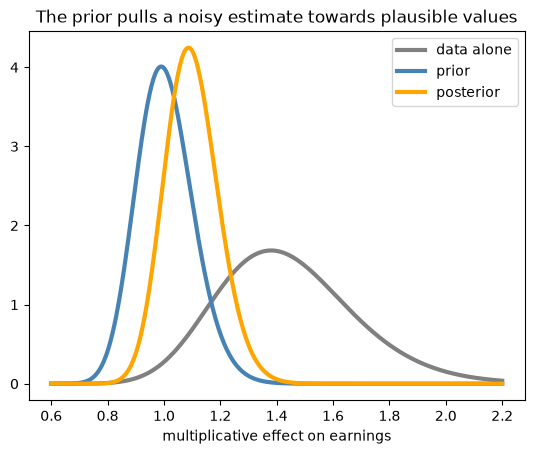

In [40]:
# FIG: bayes
# We work on the log scale, where both the estimate and the prior are normal
estimate = np.log(1.42)                 # estimated effect: earnings multiplied by 1.42
low = np.log(1.02)
high = np.log(1.98)
se = (high - low) / (2 * 1.96)          # standard error, recovered from the 95% interval

prior_mean = 0.0                        # prior: no effect on average,
prior_sd = 0.10                         # and effects usually within about 10%

# Combining = a weighted average, with weights 1 / sd^2
weight_data = 1 / se**2
weight_prior = 1 / prior_sd**2
post_mean = (weight_data * estimate + weight_prior * prior_mean) / (weight_data + weight_prior)
post_sd = 1 / np.sqrt(weight_data + weight_prior)

post_low = post_mean - 1.96 * post_sd
post_high = post_mean + 1.96 * post_sd

# np.exp takes us back from the log scale to the multiplicative factor
print("data:      factor", round(np.exp(estimate), 2),
      "  95% interval from", round(np.exp(low), 2), "to", round(np.exp(high), 2))
print("posterior: factor", round(np.exp(post_mean), 2),
      "  95% interval from", round(np.exp(post_low), 2), "to", round(np.exp(post_high), 2))

# The curves are normal on the log scale; dividing by x gives densities for the factor x
x = np.linspace(0.6, 2.2, 500)
data_curve = stats.norm.pdf(np.log(x), estimate, se) / x
prior_curve = stats.norm.pdf(np.log(x), prior_mean, prior_sd) / x
post_curve = stats.norm.pdf(np.log(x), post_mean, post_sd) / x
plt.plot(x, data_curve, color="gray", linewidth=3, label="data alone")
plt.plot(x, prior_curve, color="steelblue", linewidth=3, label="prior")
plt.plot(x, post_curve, color="orange", linewidth=3, label="posterior")
plt.xlabel("multiplicative effect on earnings")
plt.title("The prior pulls a noisy estimate towards plausible values")
plt.legend()
plt.show()

The data are weak, so the prior matters a lot: that is both the strength (more reasonable predictions) and the weakness (an extra assumption you must defend) of the Bayesian approach. With a large study the two answers would almost coincide.

## 14. Exercises (from the book, chapters 4–5)

Fill in the cells. Remember `rng` and the imports from the top of the notebook.

**Exercise 1 (book 4.1): comparing proportions.** 1000 people are contacted in a survey. Half are promised a $5 incentive. The response rate is 50 % in the treated group and 40 % in the control group. Give an estimate and standard error of the difference. Then check by simulation.

In [41]:
# your code here

**Exercise 2 (book 4.3 / 4.4): which basketball player is better?** One student shoots with 30 % accuracy, the other with 40 %. Each takes 20 shots. Simulate: what is the probability that the better shooter makes *more* shots? How large must *N* be to have a good chance to tell them apart?

In [42]:
# your code here

**Exercise 3 (book 5.1): simulating a process.** A player has a 60 % chance of making each shot, shots are independent, and he stops after missing two in a row. Write a function that simulates one game; run it 1000 times; estimate the mean and sd of the number of shots; draw the histogram.

In [43]:
# your code here

**Exercise 4 (book 5.6): propagating uncertainty.** A new technology saves $5 per unit with a standard error of $4. The market size is forecast at 40,000 with a standard error of 10,000 (independent). Use simulation to estimate the total savings with a 95 % interval.

In [44]:
# your code here

**Exercise 5 (book 5.9): the significance filter, your version.** Redo section 7.1 with a standard error of 0.05 instead of 0.17. What happens to the share of significant results and to the exaggeration factor? What does this say about *sample size*?

In [45]:
# your code here